![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | Framing and Baseline

*Project 3 — AI Product: From Model to Product*

**Team:** Jovana Krstevska
**Track:** LLM
**Data:** wikivoyage_balkans_manifest.json | wikivoyage_balkans.jsnol

---

Frame the product, look at the data, fix your evaluation before you build anything, and score the baseline your solution will have to beat.

> **Done when:** your framing is written down, you know what one row or one document is and what is wrong with the data, your test set or evaluation set is fixed, and you can say your metric and your baseline score out loud.

---
## 0. Setup

In [1]:
import os
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

from openai import OpenAI
from dotenv import load_dotenv

pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

load_dotenv()
print('Key found:', 'OPENAI_API_KEY' in os.environ)
client = OpenAI()

# Chart colours, defined once: one highlight colour, one contrast colour, a neutral grey
WINE   = "#8c2045"   # RGB (140, 32, 69)  - dark wine red
FOREST = "#4f9b63"   # RGB (79, 155, 99)  - forest green
NAVY   = "#2a5ca8"   # RGB (42, 92, 168)  - dark blue
GREY   = "#b8b6ae"   # RGB (184, 182, 174) - neutral, for "everything else"

Key found: True


---
## 1. Frame the product

Before any code. In a few sentences:

- **The user:** a hiker or nature enthusiast planning a trip to the mountains and national parks of the Balkans (Albania, Bosnia and Herzegovina, Bulgaria, Croatia, Kosovo, Montenegro, North Macedonia, Romania, and Serbia). They are at the planning stage, choosing where to go andpreparing the trip.
- **The input:** a question in plain English, such as "Which national park in Montenegro has glacial lakes?", "How much is the entry fee for Durmitor", "Where can I stay near Valbona?". Optinally the places they have already visited, so recommendations consider and skip them.
- **The output:** Short idea, built from Wikivoyage, citing the articles and sections it used, or a clear "I don't know from my guides" when it doesn't have the information.
- **The decision:** which park or mountain area to visit, how to prepare, how to get there, what it costs, where to sleep, what to look out for.
- **The metric:** (computed on the evaluation set in section 7):
    - **Retrieval hit rate at k**: the share of answerable questions where the expected article is among the top *k* chunks retrieved. If retrieval misses, the answer cannot be grounded.
    - **Grounded accuracy**: the share of answerable questions answered correctly *and* citing the expected source. This is the headline metric.
    - **Refusal on out-of-scope questions**: the share of questions the guides cannot answer (live weather, trail conditions today, places outside the region) that are correctly refused. The target is all of them, because a wrong answer here is the costliest mistake.
    - **Cost and time per question**, logged for every call.

| Mistake | Example | Cost |
|---|---|---|
| A confident wrong answer | an invented trail or hut, a wrong fee, "easy" for a hard route | **Highest**: the user acts on it, and in the mountains that can be unsafe |
| An answer with no source | correct-sounding, but the user cannot check it | High: the user cannot tell it from a wrong answer |
| A wrong refusal | "I don't know" when the guide does cover it | Low: the user searches elsewhere and loses a few minutes |

The LLM should refuse guessing an answer and every answer must have away to be checked.

---
## 2. Load the data

Run `python download_data.py` (or `python download_data.py clothing`) from the repo root first. Your files land in `data/raw/`, which is gitignored.

In [2]:
manifest = load_manifest()
print(f'Downloaded {manifest['downloaded_at']} from {manifest['source']}')
print(f'Licence: {manifest['licence']}')

articles = load_articles()
articles.shape

Downloaded 2026-11-06T10:19:16+00:00 from English Wikivoyage, https://en.wikivoyage.org
Licence: CC BY-SA 3.0/4.0 - credit 'Wikivoyage contributors' and link to each article


(619, 10)

---
## 3. First look

Shape, columns, a handful of rows **read in full**. What is one row? 

In [3]:
articles.head(10)

,pageid,title,url,country,breadcrumb,article_type,status,revid,last_edited,wikitext
0,408,Aiud,https://en.wikivoyage.org/wiki/Aiud,Romania,"[Romania, Transylvania, Alba County, Aiud]",city,outline,4877297,2024-05-08 06:40:19+00:00,"{{pagebanner|Aiud - Wikivoyage banner.jpg|Caption=The cemetery of the wooden church in Sâncrai, Alba county, Romania}}\n'''[http://www.aiud.ro Aiud]''' is a town in [[Alba County]], Romania.\n\n==..."
1,535,Alba County,https://en.wikivoyage.org/wiki/Alba_County,Romania,"[Romania, Transylvania, Alba County]",region,outline,5241329,2026-03-26 10:55:17+00:00,{{pagebanner|Alba County Wikivoyage Banner.jpg|caption= Ampoiţa}}\n'''Alba County''' is in [[Transylvania]] in [[Romania]].\n\n==Cities==\n{{mapframe}}\n* {{marker|type=city|name=[[Abrud]]|wikidat...
2,536,Alba Iulia,https://en.wikivoyage.org/wiki/Alba_Iulia,Romania,"[Romania, Transylvania, Alba County, Alba Iulia]",city,outline,5359166,2026-09-13 06:23:25+00:00,"{{pagebanner|Alba lulia Wikivoyage banner.jpg|Caption=Cetatea din Alba Iulia}}\n'''[http://www.apulum.ro/index.php/site/en Alba Iulia] ''' is a city in Western [[Transylvania]], [[Romania]]. It is..."
3,537,Albania,https://en.wikivoyage.org/wiki/Albania,Albania,[Albania],country,usable,5398514,2026-10-21 22:22:28+00:00,"{{Pagebanner|Albania banner.jpg|caption=Berat}}\n:''""AL"" redirects here. For the Brazilian state with the same postal abbreviation, see [[Alagoas]]; for the U.S. state, see [[Alabama]].''\n\n'''Al..."
4,540,Prokletije,https://en.wikivoyage.org/wiki/Prokletije,Albania,"[Albania, Northeastern Albania, Prokletije]",extraregion,unknown,5118481,2025-09-03 03:38:20+00:00,"{{pagebanner|Pagebanner default.jpg}}\n'''Prokletije''' or ([[Albanian phrasebook|Albanian]]: '''Alpet Shqiptare''' or '''Bjeshkët e Nemuna'''), sometimes called the ''Albanian Alps'' or the ''Ac..."
5,543,Albanian Riviera,https://en.wikivoyage.org/wiki/Albanian_Riviera,Albania,"[Albania, Coastal Albania, Albanian Riviera]",region,outline,5414385,2026-11-02 01:43:29+00:00,"{{pagebanner|Havana beach bar (cropped).jpg}}\nThe '''Albanian Riviera''' (Albanian: ''Bregu'') lies along the southwestern [[Coastal Albania|coast]] of [[Albania]], from the village of [[Palasë]]..."
6,130891,Alexandria (Romania),https://en.wikivoyage.org/wiki/Alexandria_(Romania),Romania,"[Romania, Muntenia, Wallachian Plain, Alexandria (Romania)]",city,outline,5386785,2026-10-12 15:14:05+00:00,"{{pagebanner|Alexandria Romania banner.jpg}}\n\n'''Alexandria''' is the county seat for [[Teleorman County]], [[Romania]].\n\n==Understand==\n[[File:Alexandria.Catedrala.2.jpg|thumb|Alexandria Cat..."
7,1212,Anina,https://en.wikivoyage.org/wiki/Anina,Romania,"[Romania, Banat, Anina]",city,outline,4727848,2023-09-12 20:52:07+00:00,"{{pagebanner|Pagebanner default.jpg}}\n'''Anina''' is a town in [[Caraș-Severin County]], [[Banat]], [[Romania]].\n\nAnina is located between [[Cheile Nerei-Beușnița National Park]] and [[Semenic-..."
8,1406,Apuseni Mountains,https://en.wikivoyage.org/wiki/Apuseni_Mountains,Romania,"[Romania, Transylvania, Apuseni Mountains]",ruralarea,outline,5311235,2026-07-16 06:20:38+00:00,"{{pagebanner|Apuseni Mountains WV Banner.jpg|caption=White Stones (Pietrele Albe), Vlădeasa Mountains, Romania}}\nThe '''Apuseni Mountains''' are a branch of the [[Carpathian Mountains]] in [[Tran..."
9,1425,Arad (Romania),https://en.wikivoyage.org/wiki/Arad_(Romania),Romania,"[Romania, Crișana, Arad (Romania)]",city,outline,5393685,2026-10-18 12:14:35+00:00,"{{pagebanner|Arad banner.jpg|pgname=Arad}}\n'''Arad''' is an industrial city of some 160,000 population (2011) at the western edge of Romania, close to the border with Hungary. It is a regional tr..."


In [4]:
articles.dtypes

pageid                        int64
title                           str
url                             str
country                         str
breadcrumb                   object
article_type                    str
status                          str
revid                         int64
last_edited     datetime64[us, UTC]
wikitext                        str
dtype: object

In [5]:
# An example of one article read in full after cleaning

example_article = articles.iloc[articles['title'] == 'Pelister National Park'].iloc[0]
for section, raw in split_sections(example_article['wikitext']):
    text = clean_wikitext(raw)
    if text:
        print(f'===== {section} ===== \n{text}\n')

===== Introduction ===== 
Pelister National Park is in Western North Macedonia near Bitola.

===== Understand ===== 
Park straddles North Macedonia's southern border with Greece, running along the magnificent Baba Mountain. Its highest peak - Pelister (2601 m) is the third-highest in North Macedonia after Korab and Titov Vrv. It is 15 km from North Macedonia's second city, Bitola, and makes for an invigorating natural escape from urban life.

Information center:
- Information center: It has permanent exhibitions rooms and souvenir shop. Hours: 09:00 - 15:30.

History:
Pelister National Park was established in 1948 and is the first national park in the country. It is also the second largest national park in North Macedonia after Mavrovo National Park.

Landscape:
Pelister is rugged and mountainous.

Flora and fauna:
Pelister National Park is filled with exquisite flora and fauna. Among flora elements, the presence is especially significant of the five-needle pine molica (Pinus peuce)- a

## Initial Observations:
- The data has 619 rows and 10 columns.
- **One row is one Wikivoyage article**. There are 619 articles about 9 countries. 
- Columns: pageid, title, URL (this will be used for citing), country, breadcrumb (the chain of regions the article sits in), article_type, status (from Wikivoyage's own tags), revid, last_edited, wikitext (the article's source markup).
- The aricle is one document and the retrival unit will be a piece of section (a chunk from a section).


---
## 4. Data quality

Empty and very short texts, HTML (`<br />`, `&#34;`), duplicates, texts in other languages, missing titles or metadata. Write down what you find and what you will do about it. Put the cleaning in a function in `src/functions.py`: the app will need it too.

In [6]:
print(example_article['wikitext'][:1500])  # print the first 1500 characters of the wikitext

{{pagebanner|Pelister National Park banner SkiLines.JPG|caption=Lines left after skiing on the snowy slopes of Baba Mountain}}
'''Pelister National Park''' is in [[Western North Macedonia]] near [[Bitola]].

==Understand==
[[File:Pelister 01.jpg|thumbnail|Pelister National Park]]
[[File:Bitolj.jpg|thumbnail|Bitola from Pelister]]

Park straddles North Macedonia's southern border with Greece, running along the magnificent Baba Mountain. Its highest peak - Pelister (2601 m) is the third-highest in North Macedonia after Korab and Titov Vrv. It is 15 km from North Macedonia's second city, Bitola, and makes for an invigorating natural escape from urban life.

===Information center===
* {{listing
| name=Information center | alt= | url=http://park-pelister.com/en/ | email=infocentarpelister@yahoo.com
| address= | lat=41.0387864 | long=21.2208491 | directions=
| phone=+389 47237010 | tollfree= | fax=
| hours=09:00  - 15:30 | price=
| content=It has permanent exhibitions rooms and souvenir shop

In [7]:
templates = articles['wikitext'].str.findall(r"\{\{\s*([A-Za-z][\w \-]*)").explode().str.strip().str.lower()
templates.value_counts().head(20)

wikitext
see            3113
sleep          1776
eat            1251
marker         1050
dead link       997
do              759
geo             619
ispartof        619
pagebanner      616
listing         528
drink           522
mapframe        447
eur             385
go              375
outlinecity     368
km              328
buy             269
flag            207
iata            183
usablecity      112
Name: count, dtype: int64

The raw text is wiki markup. The most frequent templates are **listings** (`see`, `sleep`, `eat`, `do`, `drink`, `buy`, `listing`: one per sight, hotel or restaurant, with fields for name, price, hours and a last-checked date), **maintenance and layout** templates (`dead link`, `pagebanner`, `mapframe`, `geo`, the status tags) and **unit** templates (`eur`, `km`). Listings hold much of the useful content, so they cannot be deleted.

**Decision** (implemented in `clean_wikitext()`): links keep their visible text; each listing becomes one readable line with its name, description, price, hours, directions, address and last-checked date. Unit templates keep their value (`{{eur|5}}` becomes €5); images, maps, banners, tables, references, HTML and the remaining templates are removed.

In [8]:
# the rules live in `clean_wikitext()` in src/functions.py

raw_see = dict(split_sections(example_article['wikitext']))['See']
print('BEFORE CLEANING:\n', raw_see[:700], '\n')
print('AFTER CLEANING:\n', clean_wikitext(raw_see)[:700])

BEFORE CLEANING:
 
* The '''views''' of Pelagonia valley, Lake Prespa, mountains Nidzhe, Galichica, Jakupica, and Bitola.
* The '''two mountain lakes called Pelister's Eyes'''. The Big lake is 2,218 m above the sea level while the Small lake is 2,180 m high. They are the sources of many rivers. It's possible to swim in the small one during summer time. It's about 5 hr walk from Dihovo to small lake one way.

===Dihovo village===
* There is a walk to Small and Big rocks which are local landmarks.
* Churches of Sv Nedela and Sv Nicolas.

 

AFTER CLEANING:
 - The views of Pelagonia valley, Lake Prespa, mountains Nidzhe, Galichica, Jakupica, and Bitola.
- The two mountain lakes called Pelister's Eyes. The Big lake is 2,218 m above the sea level while the Small lake is 2,180 m high. They are the sources of many rivers. It's possible to swim in the small one during summer time. It's about 5 hr walk from Dihovo to small lake one way.

Dihovo village:
- There is a walk to Small and Big rocks 

In [9]:
articles['clean_text'] = articles['wikitext'].map(clean_wikitext)
articles['n_words'] = articles['clean_text'].map(count_words)

leftover = articles['clean_text'].str.contains(r"\{\{|\}\}|\[\[|\]\]|<[a-z]+[ >]", regex=True)
print(f'Articles with markup after cleaning: {leftover.sum()}')
print(f'Duplicate page ids: {articles["pageid"].duplicated().sum()}, duplicate texts: {articles["clean_text"].duplicated().sum()}')

Articles with markup after cleaning: 2
Duplicate page ids: 0, duplicate texts: 0


In [10]:
# Article types and completeness

pd.crosstab(articles['article_type'], articles['status'], margins=True, margins_name='Total')

status,guide,outline,unknown,usable,Total
article_type,,,,,
airport,0,0,0,1,1
city,6,368,0,112,486
country,0,7,0,2,9
district,0,1,0,4,5
extraregion,0,0,4,0,4
park,1,33,0,5,39
region,0,61,0,1,62
ruralarea,0,11,0,1,12
unknown,0,0,1,0,1


In [11]:
# Articles whose type is surprising for a nature guide
articles.loc[articles["article_type"].isin(["unknown", "extraregion", "airport", "district"])
             | articles["title"].str.contains("National Park|Nature Park|Mountains", regex=True)
               & ~articles["article_type"].isin(NATURE_TYPES),
             ["title", "country", "article_type", "status", "n_words"]]

,title,country,article_type,status,n_words
4,Prokletije,Albania,extraregion,unknown,2324
19,Balkan Mountains,Bulgaria,region,outline,1397
195,Hasi,Albania,extraregion,unknown,689
230,Kiseljak,Bosnia and Herzegovina,unknown,unknown,819
327,North Montenegrin Mountains,Montenegro,region,outline,229
348,Pag,Croatia,extraregion,unknown,130
367,Pirin National Park,Bulgaria,city,outline,937
381,Polog,North Macedonia,extraregion,unknown,334
467,Skopje/Centar,North Macedonia,district,usable,4099
468,Skopje/Karpoš,North Macedonia,district,outline,1175


**Completeness is the main quality issue. 481 of 619 articles (78%) have "outline" status**. This is Wikivoyage's own label for articles that have a structure but not enough content. Only 7 are "guide" status. Thin articles mean some questions will have no answer in the data, which the assistant must recognise and refuse.

Article types also need care:
- **Pirin National Park** is tagged as a city, **Matka Canyon** as a district of Skopje (Wikivoyage files it under the Skopje article) and the **Balkan Mountains** and North Montenegrin Mountains as regions. A rule based on type alone would miss all four.
- **4 extra-hierarchical regions** (Prokletije, Hasi, Polog, Pag) and 1 article with no type (Kiseljak) have no status tag. They are kept and their type is recorded by load_articles().
- The other four Skopje districts and the airport are kept but are not nature articles: they score below the threshold and stay out of the nature subset.

In [12]:
# Empty sections

section_rows = [
    {'title':a.title, 'article_type':a.article_type, 'section': name, 'n_words':count_words(clean_wikitext(raw))}
    for a in articles.itertuples() for name, raw in split_sections(a.wikitext)
]
sections = pd.DataFrame(section_rows)
print(f'{len(sections)} sections, {(sections['n_words'] < 15).mean():.0%} with fewer than 15 words after cleaning')

7331 sections, 36% with fewer than 15 words after cleaning


In [13]:
# Checking how old is the information in the listings. Each listing (a sight, a hotel, a hut) records when it was last checked: {{see|...|lastedit=2018-10-28}}

listing_years = articles["wikitext"].str.findall(r"lastedit=(\d{4})").explode().dropna().astype(int)
print(f"{len(listing_years)} dated listings, median year {int(listing_years.median())}")
print(f"Checked in 2020 or earlier: {(listing_years <= 2020).sum()} ({(listing_years <= 2020).mean():.0%})")
print("Dated in the future:", (listing_years > pd.Timestamp.now().year).sum())
print(f"Articles last edited before 2024: {(articles['last_edited'].dt.year < 2024).sum()}")

5486 dated listings, median year 2022
Checked in 2020 or earlier: 2227 (41%)
Dated in the future: 2
Articles last edited before 2024: 55


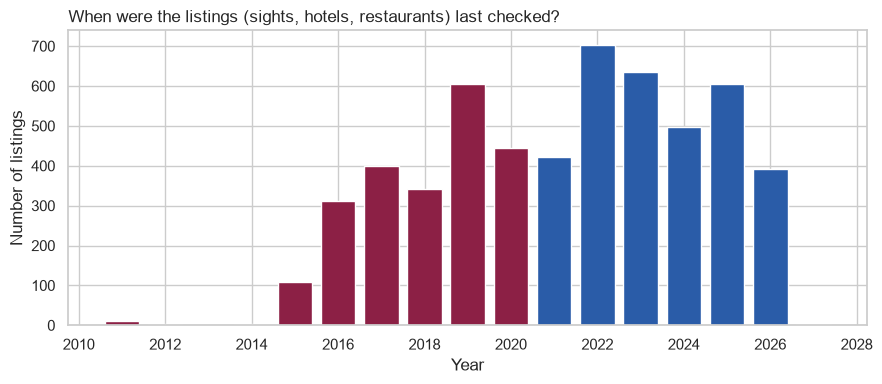

In [14]:
# Barplot showing when the listings were last checked. Listings last checked in 2020 or earlier are highlighted in wine red, the rest in navy blue.

counts = listing_years.value_counts().sort_index()
colors = [WINE if year <= 2020 else NAVY for year in counts.index]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(counts.index, counts.values, color=colors, width=0.8)
ax.set_title("When were the listings (sights, hotels, restaurants) last checked?", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Number of listings")
ax.xaxis.set_major_locator(plt.matplotlib.ticker.MultipleLocator(2))
plt.tight_layout(); plt.show()

The data is a snapshot and parts of it are stale. Total of 5486 listings, with the median lsiting last being checked in 2022.
Of 5486 dated listings, the median was last checked in 2022, and **41% were last checked in 2020 or earlier**, so prices and opening hours may be out of date. Two listings are dated in the future, a data entry error and 55 articles have not been edited since before 2024.

**Decision:** the last-checked date stays in each listing's text, so the assistant can say *"€5 per day (checked 2025)"* instead of presenting an old price as current. Questions about *current* prices or conditions belong in the out-of-scope part of the evaluation set.

In [15]:
# Personal data and information

# Business contact fields in listings: dropped by clean_wikitext()
for field in ['phone', 'email']:
    n = articles['wikitext'].str.count(rf"\|\s*{field}\s*=\s*[^|}}\s]").sum()
    print(f'Listings with a {field}: {n}')
print('Phone numbers left in the cleaned text:',
      articles['clean_text'].str.contains(r"\+\d{3}[\d ]{6,}", regex=True).sum())

# Place names with diacritics: a user may type "Zabljak" for "Žabljak"
has_diacritics = articles['title'].str.contains(r"[^\x00-\x7F]", regex=True)
print(f'Titles with non-ASCII letters: {has_diacritics.sum()} of {len(articles)}, e.g.',
      ", ".join(articles.loc[has_diacritics, 'title'].head(6)))

Listings with a phone: 3217
Listings with a email: 1214
Phone numbers left in the cleaned text: 0
Titles with non-ASCII letters: 177 of 619, e.g. Arieșeni, Bacău, Baia de Arieș, Baška, Bečej, Bečići


The listings are businesses, not private people, but they carry contact details: 3217 listings have a phone field and 1214 an email field. These fields are dropped by `clean_wikitext()` and phone numbers and emails written into the free text (214 phone numbers and 36 emails) are masked as `[phone]` and `[email]`. **No phone number is left in the cleaned text**, so none is sent to the LLM.

**177 of 619 titles (29%) contain letters with diacritics** (Žabljak, Arieșeni, Bečići). A user will often type *Zabljak*. Exact keyword search would miss these, which matters for the keyword-search baseline. The evaluation set should include at least one question spelled without diacritics.

**Data quality: summary of issues and decisions**

| Issue | Found | Decision |
|---|---|---|
| Wiki markup instead of prose | listings, maps, banners, units in every article | `clean_wikitext()`: listings to readable lines, units kept, layout removed; no markup left |
| Thin articles | 78% outline status, 36% of sections under 15 words | empty sections dropped from the chunks; questions the data cannot answer are refused |
| Surprising types | Pirin National Park as a city, 4 extra-hierarchical regions, 1 untyped | nature decided by type *or* content (5.1), not type alone |
| Old information | 41% of listings checked in 2020 or earlier; 2 dated in the future | last-checked dates kept in the text, so answers can show them |
| Contact details | phone and email fields, numbers in free text | fields dropped, numbers and emails masked |
| Diacritics | 29% of titles | accent-insensitive search; an eval question without accents |
| Duplicates | none (0 duplicate ids or texts) | nothing to do |

---
## 5. Look at the texts

Lengths, the most frequent words, how the texts differ between ratings, products or periods. Read some hard cases: the 3-star reviews, the sarcastic ones, the ones whose rating and text disagree.

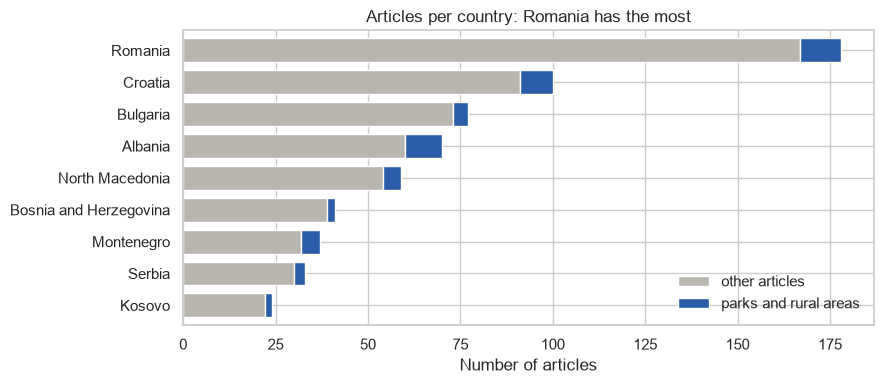

In [16]:
# Articles per country
fig, ax = plt.subplots(figsize=(9, 4))
by_country = pd.crosstab(articles["country"], articles["article_type"].isin(NATURE_TYPES))
by_country.columns = ["other articles", "parks and rural areas"]
by_country = by_country.loc[by_country.sum(axis=1).sort_values().index]
by_country.plot.barh(stacked=True, color=[GREY, NAVY], ax=ax, width=0.75, edgecolor="white", linewidth=1)
ax.set_title("Articles per country: Romania has the most")
ax.set_xlabel("Number of articles"); ax.set_ylabel("")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

In [17]:
pd.crosstab(articles["country"], articles["article_type"])

article_type,airport,city,country,district,extraregion,park,region,ruralarea,unknown
country,,,,,,,,,
Albania,1,52,1,0,2,9,4,1,0
Bosnia and Herzegovina,0,31,1,0,0,2,6,0,1
Bulgaria,0,65,1,0,0,3,7,1,0
Croatia,0,77,1,0,1,7,12,2,0
Kosovo,0,21,1,0,0,1,0,1,0
Montenegro,0,26,1,0,0,4,5,1,0
North Macedonia,0,44,1,5,1,3,3,2,0
Romania,0,145,1,0,0,8,21,3,0
Serbia,0,25,1,0,0,2,4,1,0


**Romania has 178 articles (29%).** Most of Romania's articles are about towns. The parks and rural areas (in blue) are spread more evenly, Albania ~10, Romania ~11, and Croatia ~9 having the most. **Decision:** the evaluation questions are spread across countries rather than in proportion to the articles, so the result does not mostly measure Romania.

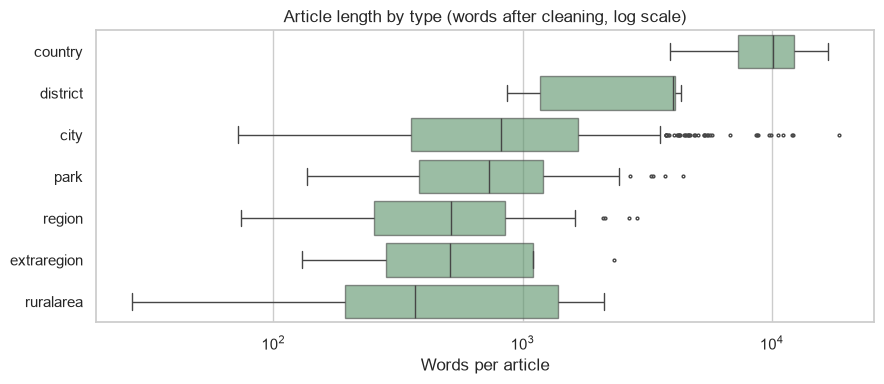

,count,min,50%,max
article_type,,,,
airport,1.0,3068.0,3068.0,3068.0
city,486.0,72.0,822.0,18548.0
country,9.0,3903.0,10156.0,16883.0
district,5.0,868.0,3999.0,4317.0
extraregion,4.0,130.0,512.0,2324.0
park,39.0,136.0,732.0,4408.0
region,62.0,74.0,516.0,2874.0
ruralarea,12.0,27.0,369.0,2115.0
unknown,1.0,819.0,819.0,819.0


In [18]:
# Article length by type
order = articles.groupby("article_type")["n_words"].median().sort_values(ascending=False).index
order = [t for t in order if (articles["article_type"] == t).sum() >= 4]

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=articles[articles["article_type"].isin(order)], x="n_words", y="article_type",
            order=order, color=FOREST, fliersize=2, ax=ax, boxprops={"alpha": 0.6})
ax.set_xscale("log")
ax.set_title("Article length by type (words after cleaning, log scale)")
ax.set_xlabel("Words per article"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

articles.groupby("article_type")["n_words"].describe()[["count", "min", "50%", "max"]].round(0)

Article length varies quite a bit: from 27 words for rural area to 18516 for city. Country articles are by far the longest with amedian of about ~10K words, parks have a median of about 730 words and regions about 515. 

**Decision:** long articles are cut into chunks of at most 250 words, so a long country article cannot crowd out a short park article in retrieval just by its size. The 9 country articles will still produce many chunks of general information, whether they help or distract will be checked in notebook 02.

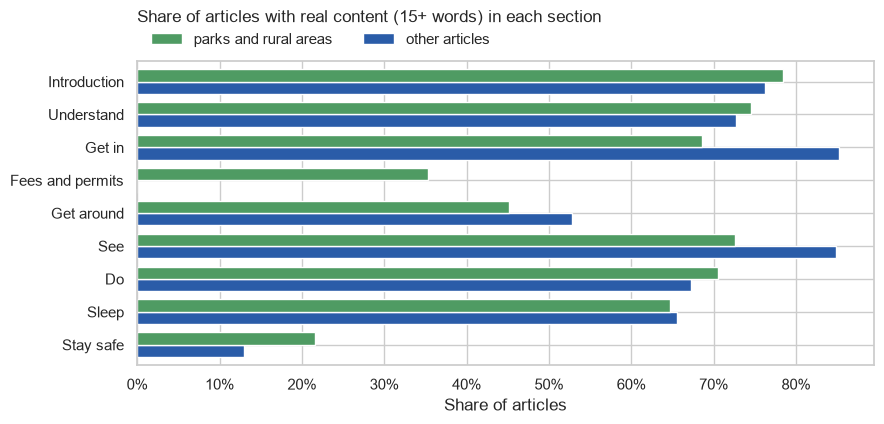

In [19]:
core = ['Introduction', 'Understand', 'Get in', 'Fees and permits', 'Get around', 'See', 'Do', 'Sleep', 'Stay safe']

filled = sections[sections['n_words'] >= 15]
is_nature_type = articles.set_index('title')['article_type'].isin(NATURE_TYPES)

share = (filled[filled['section'].isin(core)]
         .assign(group=lambda d: d['title'].map(is_nature_type).map({True: 'parks and rural areas', False: 'other articles'}))
         .groupby(['section', 'group'])['title'].nunique()
         .div(is_nature_type.value_counts().rename({True: 'parks and rural areas', False: 'other articles'}), level='group')
         .unstack().reindex(core[::-1]))

fig, ax = plt.subplots(figsize=(9, 4.4))
share[['other articles', 'parks and rural areas']].plot.barh(color=[NAVY, FOREST], ax=ax, width=0.75)
ax.set_title('Share of articles with real content (15+ words) in each section', loc='left', pad=28)
ax.set_xlabel('Share of articles'); ax.set_ylabel('')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

**"Fees and permits" exists only in parks and rural areas** and only a third of them have one with content, so many fee questions will have no answer. 
**"Stay safe" is rare everywhere** (22% of parks and rural areas, 13% of other articles) which matters for mountains and nature. Most safety questions must be limited or refused rather than guessed. Parks and rural areas are a little *less* likely than towns to have content in *Get in* and *See*. Transport information is also thinner for parks. 

These gaps decide which questions the evaluation set can and cannot expect answers to.

In [20]:
# Which articles are about nature 
articles['nature_per_1k'] = articles['clean_text'].map(nature_terms_per_1k)
articles.groupby('article_type')['nature_per_1k'].median().sort_values(ascending=False).round(1)

article_type
park           34.2
extraregion    15.4
region         12.9
ruralarea      12.8
country         6.7
district        6.0
city            4.8
airport         0.3
unknown         0.0
Name: nature_per_1k, dtype: float64

Not every article is about mountains, parks or nature in general, many of them are towns as we have seen so far. Therefore, a rule is needed to decide which articles the assistant should search. 

It has two parts: 
1. The article's type (parks and rural areas are nature by definition) 
2. How often nature and outdoor word such as: *hike, trail, peak, canyon, lake, ski, hut*, etc are used. These are already defined under: `NATURE_TERMS` in `src/functions.py`, per 1000 words.

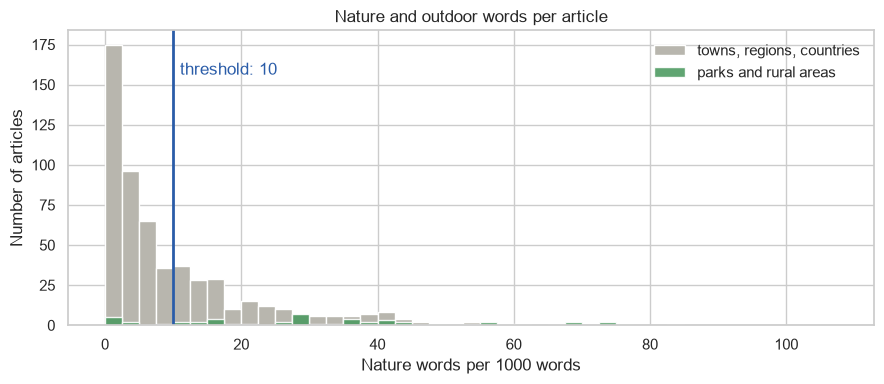

In [21]:
NATURE_THRESHOLD = 10   # nature words per 1000 words, chosen from the chart below

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 110, 2.5)
ax.hist(articles.loc[~articles['article_type'].isin(NATURE_TYPES), 'nature_per_1k'], bins=bins,
        color=GREY, label='towns, regions, countries')
ax.hist(articles.loc[articles['article_type'].isin(NATURE_TYPES), 'nature_per_1k'], bins=bins,
        color=FOREST, label='parks and rural areas', alpha=0.9)
ax.axvline(NATURE_THRESHOLD, color=NAVY, linewidth=2)
ax.text(NATURE_THRESHOLD + 1, ax.get_ylim()[1] * 0.85, f'threshold: {NATURE_THRESHOLD}', color=NAVY)
ax.set_title('Nature and outdoor words per article')
ax.set_xlabel('Nature words per 1000 words'); ax.set_ylabel('Number of articles')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [22]:
articles['is_nature'] = articles['article_type'].isin(NATURE_TYPES) | (articles['nature_per_1k'] >= NATURE_THRESHOLD)

print(f'Nature articles: {articles['is_nature'].sum()} of {len(articles)}')
print(articles.groupby('country')['is_nature'].sum().sort_values(ascending=False).to_string())

Nature articles: 247 of 619
country
Romania                   70
Albania                   39
Bulgaria                  31
Croatia                   29
North Macedonia           25
Bosnia and Herzegovina    17
Montenegro                16
Kosovo                    10
Serbia                    10


In [23]:
# Read the borderline: towns just above and just below the threshold

border = articles[~articles['article_type'].isin(NATURE_TYPES)].assign(gap=lambda d: (d['nature_per_1k'] - NATURE_THRESHOLD).abs())
cols = ['title', 'country', 'article_type', 'nature_per_1k', 'n_words', 'is_nature']

pd.concat([border[border['is_nature']].nsmallest(5, 'gap'), border[~border['is_nature']].nsmallest(5, 'gap')])[cols].round(1)

,title,country,article_type,nature_per_1k,n_words,is_nature
66,Brač,Croatia,region,10.1,397,True
118,Cres,Croatia,region,10.1,494,True
160,Elhovo,Bulgaria,city,10.1,888,True
567,Varshets,Bulgaria,city,10.1,1084,True
65,Bratuš,Croatia,city,10.2,394,True
201,Hisarya,Bulgaria,city,9.7,2277,False
409,Radoviš,North Macedonia,city,9.6,1145,False
242,Koprivshtitsa,Bulgaria,city,9.6,314,False
209,Ieud,Romania,city,9.4,106,False
531,Transylvania,Romania,region,9.4,2874,False


**The rule:** an article is a *nature article* if it is a park or a rural area **or** if at least 10 of every 1,000 words (1%) are nature and outdoor words. The threshold of 10 sits where the long tail of towns with real outdoor content begins, past the large peak of towns that barely mention nature.

It keeps **247 of 619 articles**. Reading the borderline shows the rule is imprecise right at the threshold: just above it are two Croatian islands (Brač, Cres) and small towns (Elhovo, Varshets, Bratuš), not very obviously mountain destinations. Just below it are history and culture towns (Hisarya, Koprivshtitsa) and the large Transylvania region article. Further from the threshold it does what it should: mountain bases such as Žabljak (40), Kolašin (39), Bușteni (36) and Samokov, the gateway to Rila (10.3), are in. But **Brașov (8.7)**, the base for Piatra Craiului and the Bucegi, is out: a town with a lot of other content dilutes its nature words. This is the cost of a simple rule, and the reason the nature filter is a choice to test in notebook 02 (nature articles only vs all articles), not a fixed step.

---
## 6. LLM track — the documents and the evaluation set

Skip this section on the model track.

- **Prepare the documents:** which texts the system will search (reviews, product descriptions, or both), how you chunk them, and the metadata each chunk keeps (product, rating, date, id), so that answers can cite them.
- **Write the evaluation set now, before you build:** at least 15 questions your user would really ask, each with the expected answer or the id of the source that answers it, and **at least 3 questions the data cannot answer**. Save it as a CSV in `data/` (it is small, and it is yours, so you can commit it).

In [24]:
chunks = build_chunks(articles)
chunks['is_nature'] = chunks['title'].map(articles.set_index('title')['is_nature'])

print(f"{len(chunks)} chunks from {chunks['title'].nunique()} articles. {chunks['is_nature'].sum()} chunks from nature articles")

chunks[['chunk_id', 'title', 'country', 'section', 'n_words', 'text']].sample(5, random_state=RANDOM_STATE)

11510 chunks from 618 articles. 3291 chunks from nature articles


,chunk_id,title,country,section,n_words,text
4630,wv-4630,Kukës,Albania,Understand,33,2000. It is the only town in the world that has been nominated for a Nobel Peace Prize. It received this honour for receiving hundreds of thousands of refugees from the Kosovo War.
2802,wv-2802,Dubrovnik-Neretva,Croatia,Drink,31,"- Lots of decent Croatian draught beer and wine in the many town & beach bars.\n- The local distilled spirit is rakija, the best known being šljivovica or plum brandy."
7524,wv-7524,Rijeka,Croatia,Sleep,105,"4 hotel suites on two floors. All rooms are equipped with a TV and a direct telephone line, while the access to the Internet is possible via modem, using the telephone connection port in the room...."
9679,wv-9679,Targovishte,Bulgaria,See,105,"then resurrected and taken bodily into Heaven; the feast day of the Dormition is 15 August. Directions: from the Ethnographic Museum, go north along Georgi S. Rakovski Str and look to the left. (L..."
10018,wv-10018,Tirana International Airport Nënë Tereza,Albania,Understand,105,This is Albania's main airport with numerous connections to all over Europe and a few connections to Asia and the Middle East. Tirana’s aviation history began in 1926 with domestic services by Ger...


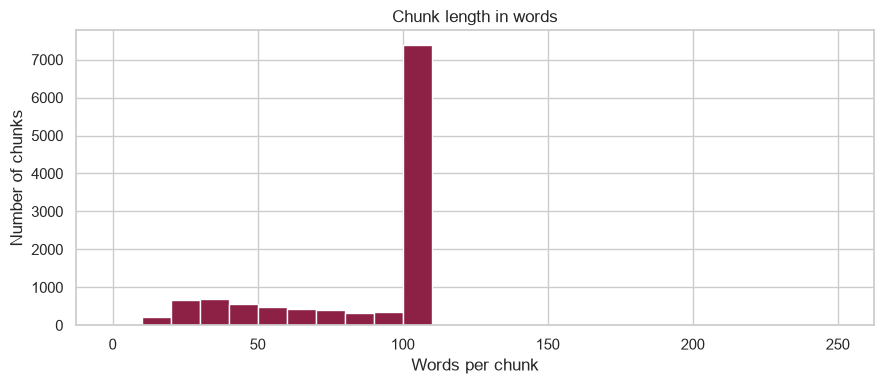

section
See             2710
Get in          1453
Understand      1260
Do              1182
Sleep            957
Eat              835
Get around       822
Introduction     505
Drink            446
Buy              414
dtype: int64

In [25]:
# Chunk length distribution

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(chunks['n_words'], bins=np.arange(0, 260, 10), color=WINE)
ax.set_title('Chunk length in words')
ax.set_xlabel('Words per chunk'); ax.set_ylabel('Number of chunks')
plt.tight_layout() 
plt.show()

chunks.groupby('section').size().sort_values(ascending=False).head(10)

In [26]:
save_chunks(chunks)
print(f'Saved to {CHUNKS_FILE.relative_to(ROOT)}')

Saved to data/processed/chunks.jsonl


**One document is one Wikivoyage article, one retrieval unit is one chunk.** Each article is split at its level-2 sections (Understand, Get in, Fees and permits, Do, Sleep, Stay safe, ...), each section is cleaned, and sections longer than 150 words are cut into windows of 150 words that overlap by 30, so a sentence on a boundary is not lost, and MiniLM reads at most 256 tokens. Sections are a natural unit here, because the sections are where the questions point (*how do I get in, what does it cost, where do I sleep*).

Dropped: "Go next" and "Connect" (links to other places and phone networks, no content of their own) and sections with fewer than 15 words (the empty skeletons from 4.4).

Each chunk keeps the metadata an answer has to cite: `chunk_id`, article title, country, article type, section, URL and last-edited date. `embed_text` adds the article and section names in front of the text, so a chunk like *"Entry is €5 per day"* still says which park it is about.

All articles are chunked, with `is_nature` kept as a column: searching only nature articles or all of them is one of the design choices to compare in notebook 02.

**6,364 chunks from 618 articles** Around 4.5K chunks are full 150-word windows cut from long sections, the rest are full sections. *See*, *Get in*, *Understand* and *Do* produce the most chunks.

Chunk size and overlap are a first choice, not a tuned one: 150 words keeps most sections whole while staying small enough for precise retrieval. 

Evaluation set is built and can be found under `/data/eval_questions.csv`. It contain 18 questions the guide can answer and four out of scope questions.

In [27]:
eval_questions = pd.read_csv('../data/eval_questions.csv')
display(eval_questions)

,question_id,kind,country,question,expected_title,expected_section,expected_answer
0,q01,fact,Montenegro,How much is the entry fee for Durmitor National Park?,Durmitor National Park,Fees and permits,€5 per day (checked 2025).
1,q02,fact,Croatia,How much does an adult ticket to Plitvice Lakes cost in July?,Plitvice Lakes National Park,Fees and permits,€40 for adults (1 June-30 September); €26.50 if entering after 4 PM in June-August.
2,q03,practical,Albania,Can I drive to Theth in winter?,Thethi,Get in,No: the road (SH21 from Koplik) is closed from November to April.
3,q04,fact,Albania,"How long does the hike from Theth to Valbona take, and how hard is it?",Thethi,Do,"6-8 hours, via the Valbona Pass (1814 m); difficulty T2; marked red and white."
4,q05,recommendation,Kosovo,Where can I try a via ferrata in Kosovo?,Rugova Mountains,Via Ferrata,"In the Peja-Rugova Gorge (Rugova Mountains): 4 via ferrata trails, 300-1000 m long, reaching up to 300 m in height."
5,q06,practical,Romania,Do I need a permit or a ticket to hike in Retezat National Park?,Retezat National Park,Fees and permits,"No permit or fee is needed; there are no bins, not even at huts, so carry your rubbish out."
6,q07,safety,Albania,Is it safe to hike off the marked trails around Valbona?,Valbona Valley National Park,Stay safe,"Take care: unexploded ordnance from the Kosovo conflict is an issue off the beaten path, and the UK, Australia and Canada advise against travel to the Tropoja district, although law and order has ..."
7,q08,fact,North Macedonia,"What are Pelister's Eyes, and can I swim there?",Pelister National Park,See,"Two mountain lakes: the Big lake at 2,218 m and the Small lake at 2,180 m; swimming is possible in the small one in summer; about a 5-hour walk from Dihovo, one way."
8,q09,safety,Romania,What should I watch out for when hiking in Piatra Craiului?,Piatra Craiului National Park,Stay safe,"Bears, especially in spring when they have cubs (back away slowly, do not run, make noise), and shepherd dogs guarding flocks (call the shepherd, carry a stick)."
9,q10,fact,Bulgaria,"What is the highest peak on Vitosha, and is there an easy way up?",Vitosha,Do,"Cherni Vrah, 2290 m; a lift from an outer neighbourhood of Sofia goes to just below the summit."


---
## 7. The baseline

The simplest thing that could work, scored with the same evaluation as your final solution.

- **Model track:** a `DummyClassifier`, then TF-IDF with logistic regression, scored with cross-validation on the training set.
- **LLM track:** the LLM alone (no retrieval, no tools) on your evaluation set, or a keyword search (TF-IDF) for the retrieval part. Log the tokens and the cost.

In [28]:
eval_set = load_eval_set()
llm_answers = run_llm_baseline(client, eval_set)

review = eval_set[['question_id', 'kind', 'question', 'expected_answer']].merge(llm_answers, on='question_id').rename(columns={'answer': 'llm_answer'})
review[['question_id', 'kind', 'question', 'expected_answer', 'llm_answer', 'looks_like_refusal']]

,question_id,kind,question,expected_answer,llm_answer,looks_like_refusal
0,q01,fact,How much is the entry fee for Durmitor National Park?,€5 per day (checked 2025).,"I don't know. Entry fees for Durmitor National Park can vary depending on the specific area/season (e.g., certain trailheads or zones may differ), so I can’t confirm the current amount.",True
1,q02,fact,How much does an adult ticket to Plitvice Lakes cost in July?,€40 for adults (1 June-30 September); €26.50 if entering after 4 PM in June-August.,I don't know.,True
2,q03,practical,Can I drive to Theth in winter?,No: the road (SH21 from Koplik) is closed from November to April.,"Yes, but usually only with a suitable vehicle (4x4, winter tires) and only if roads are plowed—access to Theth can be blocked by snow/landslides from late autumn through winter. The safest plan is...",True
3,q04,fact,"How long does the hike from Theth to Valbona take, and how hard is it?","6-8 hours, via the Valbona Pass (1814 m); difficulty T2; marked red and white.",The Theth → Valbona hike usually takes about 5–8 hours (around 15–20 km depending on the route and conditions) and is considered moderate to challenging. The main difficulty is the mountain terrai...,False
4,q05,recommendation,Where can I try a via ferrata in Kosovo?,"In the Peja-Rugova Gorge (Rugova Mountains): 4 via ferrata trails, 300-1000 m long, reaching up to 300 m in height.",I don't know.,True
5,q06,practical,Do I need a permit or a ticket to hike in Retezat National Park?,"No permit or fee is needed; there are no bins, not even at huts, so carry your rubbish out.",I don't know.,True
6,q07,safety,Is it safe to hike off the marked trails around Valbona?,"Take care: unexploded ordnance from the Kosovo conflict is an issue off the beaten path, and the UK, Australia and Canada advise against travel to the Tropoja district, although law and order has ...","I don’t know. For the Valbona area, off-trail hiking can be risky due to steep terrain, sudden weather changes, and potential route-finding issues, so it’s best to rely on established marked paths...",True
7,q08,fact,"What are Pelister's Eyes, and can I swim there?","Two mountain lakes: the Big lake at 2,218 m and the Small lake at 2,180 m; swimming is possible in the small one in summer; about a 5-hour walk from Dihovo, one way.","Pelister’s “Eyes” (often called the “Pelister Eyes”/“Pelisterove oči”) are natural karst springs/rock pools near Mount Pelister in North Macedonia, formed by water emerging from the mountains. Whe...",True
8,q09,safety,What should I watch out for when hiking in Piatra Craiului?,"Bears, especially in spring when they have cubs (back away slowly, do not run, make noise), and shepherd dogs guarding flocks (call the shepherd, carry a stick).","When hiking in Piatra Craiului, watch for sudden weather changes (fog, rain, and cold winds), rocky/slippery sections especially after rain, and exposed narrow passages that can be risky if you’re...",False
9,q10,fact,"What is the highest peak on Vitosha, and is there an easy way up?","Cherni Vrah, 2290 m; a lift from an outer neighbourhood of Sofia goes to just below the summit.","The highest peak on Vitosha is **Vitosha Peak (Черни връх / Cherni Vruh)** at **1,809 m**. A relatively easy way up is the **“Gold Diggers” / “Zlatnite Mostove” route** from **Alekо (near Dragalev...",False


**Labelling.** Reading each answer next to the expected one and labelling it:

| label | answerable questions | out-of-scope questions |
|---|---|---|
| `correct` | matches the expected answer | - |
| `partial` | right in part, with something missing or wrong | - |
| `wrong` | a different, outdated or made-up answer | answered instead of refusing |
| `refused` | said it doesn't know | said it doesn't know (the right outcome) |

In [29]:
LABELS = {   # question_id: (label, short reason)
    "q01": ("refused", ""),
    "q02": ("refused", ""),
    "q03": ("wrong", "clearly states it's not allowed with dates specified"),
    "q04": ("correct", ""),
    "q05": ("refused", ""),
    "q06": ("refused", ""),
    "q07": ("refused", ""),
    "q08": ("partial", "it explains the question, but doesn't provide the full answer"),
    "q09": ("partial", "provides an answer but it differs"),
    "q10": ("correct", ""),
    "q11": ("refused", ""),
    "q12": ("refused", ""),
    "q13": ("partial", "starts with a 'yes' but it continues to explain swimming is not allowed"),
    "q14": ("correct", ""),
    "q15": ("correct", ""),
    "q16": ("correct", ""),
    "q17": ("refused", ""),
    "q18": ("refused", ""),
    "q19": ("refused", ""),
    "q20": ("wrong", "it answered instead of refusing"),
    "q21": ("refused", ""),
    "q22": ("refused", ""),
}

labels = pd.DataFrame([(q, label, reason) for q, (label, reason) in LABELS.items()],
                      columns=["question_id", "label", "reason"])
missing = labels.loc[labels["label"] == "", "question_id"].tolist()
if missing:
    print(f"Still to label: {missing}")

In [31]:
llm_results = review.merge(labels, on="question_id").assign(cites_source=False)
llm_scores = labels_summary(llm_results)
def format_score(name, value):
    """Shares as percentages, dollars with 5 decimals, seconds with 1."""
    if "USD" in name:
        return f"${value:.5f}"
    if "seconds" in name:
        return f"{value:.1f} s"
    return f"{value:.0%}"

llm_scores.to_frame("LLM alone").assign(**{"LLM alone": [format_score(n, v) for n, v in llm_scores.items()]})

,LLM alone
answerable: correct,28%
answerable: partial,17%
answerable: wrong,6%
answerable: refused,50%
answerable: grounded accuracy,0%
out of scope: refused,75%
cost per question (USD),$0.00010
total cost (USD),$0.00225
overall accuracy (all questions),36%
answerable: lenient accuracy (partial = 0.5),36%


In [32]:
# Answers marked as wrong or partial with the reason
llm_results[llm_results["label"].isin(["wrong", "partial"])][["question_id", "kind", "question", "expected_answer", "llm_answer", "reason"]]

,question_id,kind,question,expected_answer,llm_answer,reason
2,q03,practical,Can I drive to Theth in winter?,No: the road (SH21 from Koplik) is closed from November to April.,"Yes, but usually only with a suitable vehicle (4x4, winter tires) and only if roads are plowed—access to Theth can be blocked by snow/landslides from late autumn through winter. The safest plan is...",clearly states it's not allowed with dates specified
7,q08,fact,"What are Pelister's Eyes, and can I swim there?","Two mountain lakes: the Big lake at 2,218 m and the Small lake at 2,180 m; swimming is possible in the small one in summer; about a 5-hour walk from Dihovo, one way.","Pelister’s “Eyes” (often called the “Pelister Eyes”/“Pelisterove oči”) are natural karst springs/rock pools near Mount Pelister in North Macedonia, formed by water emerging from the mountains. Whe...","it explains the question, but doesn't provide the full answer"
8,q09,safety,What should I watch out for when hiking in Piatra Craiului?,"Bears, especially in spring when they have cubs (back away slowly, do not run, make noise), and shepherd dogs guarding flocks (call the shepherd, carry a stick).","When hiking in Piatra Craiului, watch for sudden weather changes (fog, rain, and cold winds), rocky/slippery sections especially after rain, and exposed narrow passages that can be risky if you’re...",provides an answer but it differs
12,q13,comparison,"Which is cheaper to enter, Durmitor or Biogradska Gora National Park?","Biogradska Gora: €3 (as of August 2013, so possibly outdated); Durmitor: €5 per day (2025).","I don't know. Prices for park entry in Montenegro are often not fixed the same way as ticketed attractions and can vary by season or current rules, so I can’t reliably compare Durmitor vs Biograds...",starts with a 'yes' but it continues to explain swimming is not allowed
19,q20,out_of_scope,What are the best hikes in Triglav National Park?,"REFUSE: Triglav is in Slovenia, outside the region covered.","Some of the best hikes in Triglav National Park (Slovenia) include the Triglav Lakes (Dolinsko/Triglawska jezera) route, the Via Alpina sections around Vogel–Kredarica, the climb to Triglav via th...",it answered instead of refusing


In [33]:
llm_results.to_csv(BASELINE_LABELS_FILE, index=False)

---
## 8. What the baseline tells you

In prose: how good is the baseline, which mistakes does it make, and what do you expect your solution to fix?

- **The LLM alone:** of the 18 questions the guides can answer, it answered 28% correctly (5), 17% partly, 6% wrongly and refused 75%. On the 4 questions the guides cannot answer, it correctly said it did not know for 3 (75%), but answered 1 anyway. None of its answers cite a source, so even the correct ones cannot be checked.
- **For the user:** a hiker could not rely on these answers. A right answer and a wrong one look the same, with nothing to check them against, so the user cannot tell which to trust.
- **The scores to beat:** overall accuracy is 36% (8 of 22: correct answers plus correct refusals), and grounded accuracy (correct *and* citing the right source) is 0%, because nothing is cited. The answers exist in the guides, so the RAG pipeline should raise both. The target: most answerable questions answered correctly with the right source, every out-of-scope question refused, at $0.000010 per question. With 18 questions each one is worth about 6 percentage points, so small differences should not be over-read.